# Lab 2: Belt

In [16]:
# Pulley - Class 2

# Import statements
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt
import math

import MechDesign.Helpers as HM

from MechDesign.Units.Units import m_, mm_, kg_, s_, N_, rpm_, W_, deg_, mu_m_
import MechDesign.Units.UnitMethods as UM

import MechDesign.RnM as RnM

**Problem description**

The drive of a gearbox is to be designed as a *narrow profile V-belt* according to the requirements of the lab asignment. The chosen three-phase motor 160L has a drive power $P_{motor}= 15kW$ at a speed of $n=1500rpm$.

Motor selection: 

- $P_{Motor} = 15.0\text{ kW}$
- $\eta = 0.90$
- $K_A = 1.35$


Ratio calculation: 
- $i_g = 4.089$
- $i_b = 2.454$
- $i_{total} = 10.03$



The calculation is carried out according to the flowchart shown in Figure 16-18

---

### Determining the type of belt

Narrow DIN 2211 profile V-belt as specified of the lab assignment

### Determining disc diameters

According to the table 16-21 corresponding **minimum** driving pulley diameter for the asynchronous motor is $D_{dk} = 140mm$.  To determine the driving pulley diameter the $P/n$ ratio is evualuted as following.  
$$P/n = 15kW/1500 min^{-1} = 0.01 kW*min $$

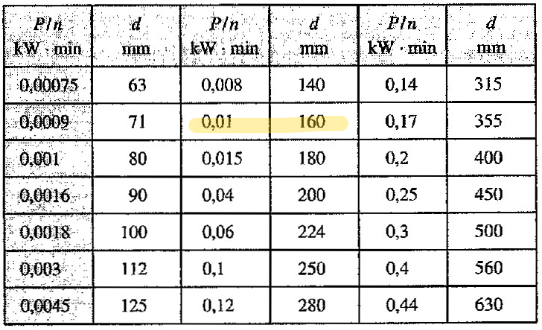

According to the table 16-7, diameter of the smallest pulley diameter is $D_{dk}=160mm$ 

In [18]:
# Defining the belt to be calculated
BT = RnM.Belt()     #--- since Belt is part of the RnM library we call it as a part of it ---

BT.d_dg = BT.E16_20A_LargeDiskDiameter()

HM.EqPrint('d_dg',BT.d_dg)
HM.MyHelp(BT.d_dg)

BT.d_dk = 160*mm_
BT.i = 2.454

d_dg = HM.substitute(BT.d_dg ,BT) 
HM.EqPrint('d_dg', d_dg)  
t=0

Eq(d_dg, _d_dk*_i)

_d_dk*_i

    i : [] transmission ratio (equivalent to gear ratio in case of gears)
    d_dk : [mm] reference diameter of smaller disk, note explenation equation 16-36


Eq(d_dg, 392.6*mm_)


**The answer to section a. is:**

- $d_{dg} = 400mm$
- $d_{dk} = 160mm$

---


#### b. Center Distance $e$ and Belt Length $L_d$


Center distance formula for V- and poly- V- belts according to equation 16.21 of the book: 
$$0.7 \cdot (d_g + d_k) \le e' \le 2 \cdot (d_g + d_k) $$


In [20]:
# equations for the limits of the center distance

BT.eprime_LL = BT.E16_21A_ShaftDistanceLowerLimit()
BT.eprime_UL = BT.E16_21_ShaftDistanceUpperLimit()
BT.Lprime = BT.E16_23_TheoreticalBeltLength()

In [22]:
BT.d_dg = 400 * mm_  #--- diameter of the driven pulley ---
BT.d_dk = 160 * mm_  #--- diameter of the driving pulley - --


eprime_LL = HM.substitute(BT.eprime_LL,BT) 
eprime_UL = HM.substitute(BT.eprime_UL,BT)
Lprime = HM.substitute(BT.Lprime,BT)
HM.EqPrint('eprime_LL',eprime_LL) 
HM.EqPrint('eprime_UL',eprime_UL)
t=0


Eq(eprime_LL, 386.8*mm_)

Eq(eprime_UL, 1105.0*mm_)

In [23]:
BT.L_d = 2500*mm_  #--- belt length ---
BT.e = BT.E16_22_FinalShaftDistance().evalf()

BT.e = UM.RemoveUnits(BT.e)  *mm_    #this will first remove the units and then add mm again, avoiding the mm**1
HM.EqPrint('e',BT.e)
t=0

Eq(e, 801.2*mm_)

 According to DIN 323 R40, belt length is chosen.
 

<>:40: SyntaxWarning: invalid escape sequence '\p'
<>:40: SyntaxWarning: invalid escape sequence '\p'
C:\Users\tseen\AppData\Local\Temp\ipykernel_3436\57344228.py:40: SyntaxWarning: invalid escape sequence '\p'
  ax.set_title('Center distance $e^\prime$ vs Belt Length $L^\prime$')


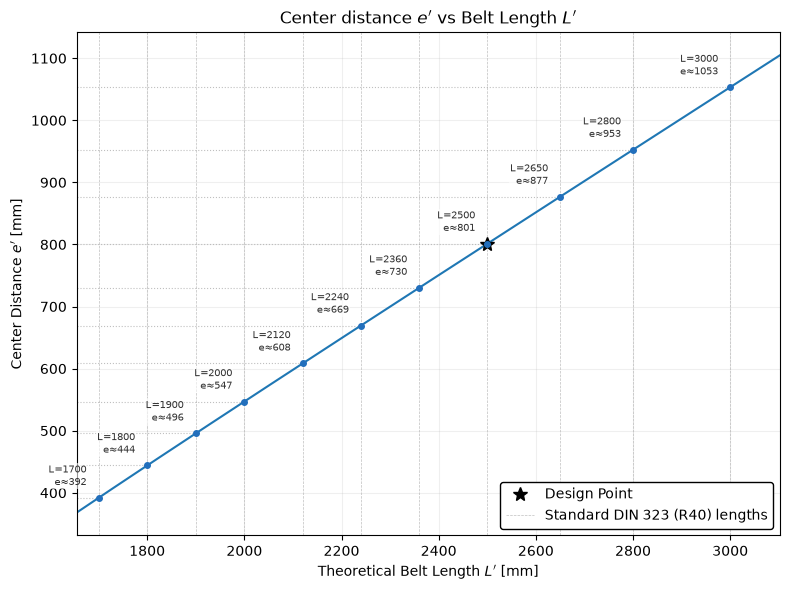

In [24]:
eprime_values = np.arange(368, 1105.0, 0.1)
Lprime_values = HM.evaluate(BT.E16_23_TheoreticalBeltLength(), {'eprime': eprime_values})

fig, ax = plt.subplots(figsize=(8, 6))

# Define Standard DIN 323 R40 Series Base Numbers
# ISO 3 / DIN 323 rounded standard values
din_r40_base = [1.00, 1.06, 1.12, 1.18, 1.25, 1.32, 1.40, 1.50, 1.60, 1.70, 
                1.80, 1.90, 2.00, 2.12, 2.24, 2.36, 2.50, 2.65, 2.80, 3.00, 
                3.15, 3.35, 3.55, 3.75, 4.00, 4.25, 4.50, 4.75, 5.00, 5.30, 
                5.60, 6.00, 6.30, 6.70, 7.10, 7.50, 8.00, 8.50, 9.00, 9.50, 10.00]

# Generate standard belt lengths (x100 and x1000 scales)
all_standard_lengths = sorted(list(set(
    [int(val * 1000) for val in din_r40_base]
)))

# Filter to only the lengths that fit inside your plotted X-axis data
x_min = np.min(Lprime_values)
x_max = np.max(Lprime_values)
valid_lengths = [L for L in all_standard_lengths if x_min <= L <= x_max]

# Plot Main Relationship Curve
ax.plot(Lprime_values, eprime_values)
point = ax.plot(2500, 801, 'k*', ms=10, label='Design Point')

# Mark All Standard DIN Lengths within Range
for i, L_std in enumerate(valid_lengths):
    # Interpolate to find exact center distance for this standard length
    e_std = np.interp(L_std, Lprime_values, eprime_values)
    label = 'Standard DIN 323 (R40) lengths' if i == 0 else None
    ax.axvline(L_std, color='gray', linestyle='--', linewidth=0.5, alpha=0.5, label=label, zorder=1)
    ax.hlines(y=e_std, xmin=x_min, xmax=L_std, color='gray', linestyle=':', linewidth=0.8, alpha=0.5, zorder=1)
    ax.plot(L_std, e_std, marker='o', color="#226FBC", markersize=4, zorder=5)
    ax.text(L_std - 25, e_std + 15, f'L={L_std}\ne\u2248{e_std:.0f}', 
            color='#333333', fontsize=7.5, va='bottom', ha='right',
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.6, pad=0.5))

# Axes, Layout, and Styling
ax.set_title('Center distance $e^\prime$ vs Belt Length $L^\prime$')
ax.set_xlabel(r"Theoretical Belt Length $L^\prime$ [mm]")
ax.set_ylabel(r"Center Distance $e^\prime$ [mm]")
ax.set_xlim(left=x_min, right=x_max)

ax.grid(True, linestyle='-', alpha=0.2, zorder=0)
ax.legend(loc='lower right', framealpha=1.0, edgecolor='black')

plt.tight_layout()
plt.show()



- $D_{dk} = 160mm$
- $D_{dg} = 400mm$
-  $e = 801mm$
- $L = 2500mm$


---

## $P_{nominal}, c_1, c_2, U_z$ 



Nominal power per belt for narrow profile V-belts, table 16-15

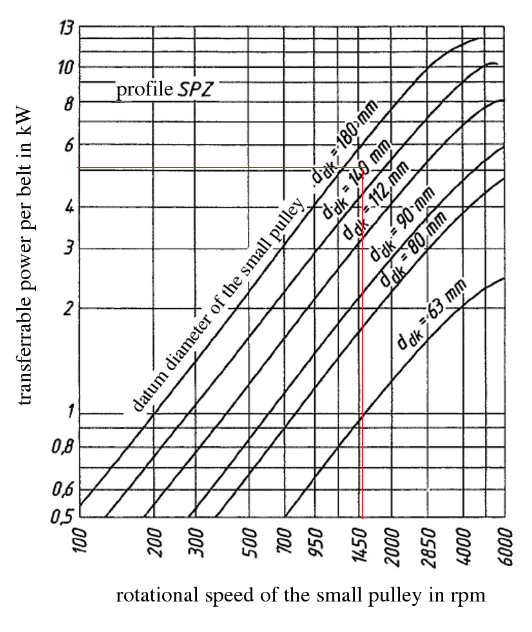

Angle factor $c_1$ for narrow profile V-belts, table 16-17

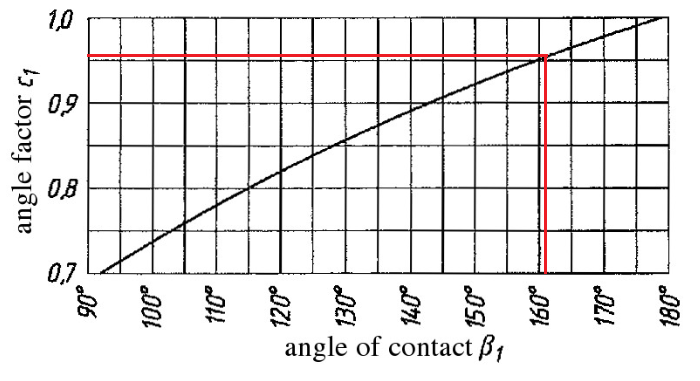

Length $c_2$ for narrow profile V-belts, table 16-17

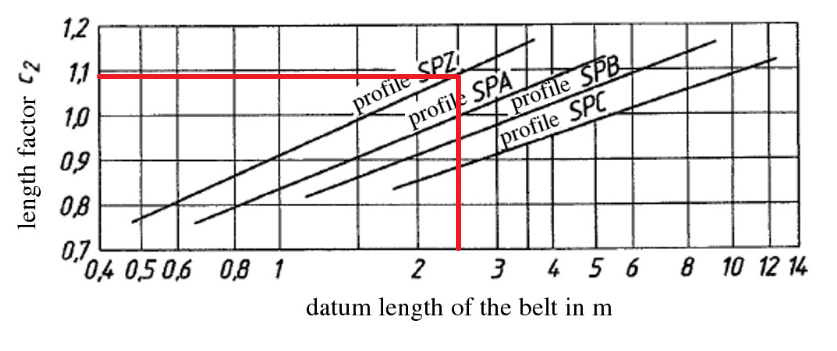

Power - transmission ratio factor for narrow profile V-velts table 16-16

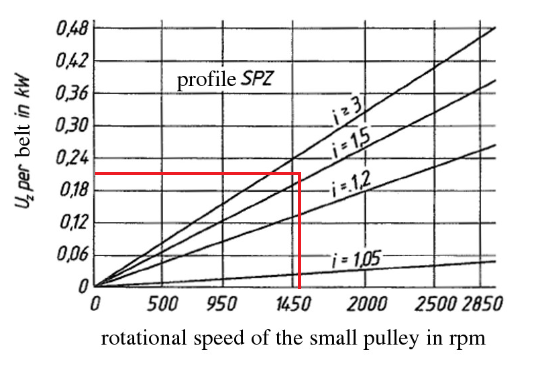

## Calculation for wrap angle

The wrap angle $B_k$ together with the coefficient of friction $\mu$ determines to the efficiency and the useful force transmission.
 
 => Large wrap angles require lower contact pressure thus a lower shaft load.

In [26]:
BT.beta_k = BT.E16_24A_circumfranceAngle()
HM.EqPrint('beta_k',(BT.beta_k)/3.14*180*deg_)
HM.EqPrint('beta_k',BT.beta_k)
t=0

Eq(beta_k, 162.9*deg_)

Eq(beta_k, 2.841)

## Calculation for number of belts



Formula 16.28 for required number of V-belts or ribs: 

$$ z \ge \frac{P'}{(P_N + U_z) \cdot c_1 \cdot c_2} = \frac{K_A \cdot P_{\text{nom}}}{(P_N + U_z) \cdot c_1 \cdot c_2} $$


* **$K_A$**: Operating factor to consider the dynamic operating conditions; if no factory data is available, values according to table 3-5
* *$P_{\text{nom}}$**: The rated power to be transmitted by the V-belt drive
* **$P_N$**: The nominal power to be transmitted by one V-belt or one rib; values according to table 16-15
* **$U_z$**: Transfer surcharge for $i > 1$; values according to table 16-16
* **$c_1$**: Angle factor; values for $\beta_1 \le 180^\circ$ according to table 16-17
* **$c_2$**: Length factor that takes into account the power change when the actual target length $L_d$ differs from the 'reference belt length'; values according to table 16-17



In [29]:

BT.z = BT.E16_29_NumberOfBelts()
BT.Pprime = BT.P * BT.K_A

BT.P = 8000*W_
BT.K_A = 1.7


BT.P_N = 4600*W_  # table 16-15b  1500rpm and 160mm diameters
BT.U_z = 210*W_   # table 16-16b, 1500rpm and i=2.454
BT.c_1 = 0.96     # table 16-17a  beta_K 162.78°
BT.c_2 = 1.085     # table 16-17c SPZ 2500mm belt,


HM.EqPrint('z',BT.z)
t=0

Eq(z, 2.715)

## Circumferential force, belt speed, bending frequency 


$$ F_t = \frac{P'}{v} = \frac{K_A \cdot P_{nom}}{v} = \frac{K_A \cdot T_{nom}}{(d_d / 2)} \quad (16.27) $$

* **$P', P_{nom}$**: Calculation power, power to be transferred
* **$K_A$**: Service factor, if no manufacturer's specifications are available, $K_A$ according to table 3-5
* **$d_d$**: Disc guideline diameter (for flat belts $d$)
* **$v$**: Belt speed according to $v = d_d \cdot \pi \cdot n$



In [32]:
BT.n = 1500*rpm_
BT.zz = 3

BT.F_t =  BT.E16_27_FrictionForce()
BT.v = UM.All_to_SI( BT.d_dk/2*BT.n)

HM.EqPrint('v',BT.v)
HM.EqPrint('F_t',UM.kgm_s2_to_N( UM.All_to_SI(BT.F_t)))

BT.f_B =UM.All_to_SI( BT.E16_37_BendingFrequency())
t=HM.EqPrint('f_B',BT.f_B)
t=0

Eq(v, 12.57*m_/s_)

Eq(F_t, 1082.0*N_)

Eq(f_B, 15.08/s_)

Plot the graphs for axial load w.r.t: 
    
$F_a$ vs $P, rpm, \eta, diameter$

$$F_a = \frac{F_t \sqrt{m^2 + 1 - 2m \cos(\beta_1)}}{m - 1}$$




In [38]:
BT.mu = 0.4
BT.n_1 = BT.n
BT.beta_1 = BT.beta_k   



T  = UM.kgm_s2_to_N( UM.All_to_SI( BT.Pprime / BT.n_1))
HM.EqPrint('T',T)
BT.F_t = BT.Pprime / BT.v
HM.EqPrint('F_t',UM.kgm_s2_to_N( UM.All_to_SI(BT.F_t)))
BT.muprime = BT.E16_1B_Set2muprime()
BT.mu = BT.muprime
HM.EqPrint('mu',BT.mu)
BT.m = BT.E16_3_Eytelwein()
HM.EqPrint('m',BT.m)
BT.F_a = UM.kgm_s2_to_N( UM.All_to_SI(BT.E16_6_AxleLoad()))
t=HM.EqPrint('F_a',BT.F_a)


Eq(T, 86.58*N_*m_)

Eq(F_t, 1082.0*N_)

Eq(mu, 1.229)

Eq(m, 32.8)

Eq(F_a, 1149.0*N_)